Downloading and Importing Required libraries

In [1]:
!pip install yfinance

In [2]:
import sys
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import date
import requests
from io import StringIO
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import fcluster
from importlib.metadata import version

In [3]:
package_versions = pd.DataFrame({
    "Package": [
        "Python", "pandas", "NumPy", "Seaborn",
        "Matplotlib", "yfinance", "requests",
        "scikit-learn", "SciPy"
    ],
    "Version": [
        sys.version.split()[0],
        version("pandas"),
        version("numpy"),
        version("seaborn"),
        version("matplotlib"),
        version("yfinance"),
        version("requests"),
        version("scikit-learn"),
        version("scipy")
    ]
})

display(package_versions)

,Package,Version
0,Python,3.13.18
1,pandas,2.2.3
2,NumPy,2.4.6
3,Seaborn,0.13.2
4,Matplotlib,3.10.0
5,yfinance,0.2.66
6,requests,2.32.4
7,scikit-learn,1.6.1
8,SciPy,1.16.3


1.1
Retrieving the tickers

In [4]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

tables = pd.read_html(StringIO(response.text))

sp500 = tables[0]

# Extract ticker symbols, company names and sector classifications
sp500_tickers = sp500[
    ["Symbol", "Security", "GICS Sector"]
].copy()

# Rename Security to Company
sp500_tickers = sp500_tickers.rename(
    columns={"Security": "Company"}
)

ticker_df = sp500_tickers.copy()

retrieval_date = date.today()

# Save extracted data
sp500.to_csv("sp500_ticker_list.csv", index=False)
ticker_df.to_csv("sp500_tickers.csv", index=False)

print("Retrieval date:", retrieval_date)
print("Number of companies:", len(ticker_df))
print("Number of sectors:", ticker_df["GICS Sector"].nunique())

display(ticker_df.head(10))


Retrieval date: 2026-11-25
Number of companies: 503
Number of sectors: 11


,Symbol,Company,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [5]:
start_date = "2021-01-01"
end_date = "2025-01-01"

tickers = sp500_tickers["Symbol"].tolist() + ["^GSPC"]

print("Number of tickers:", len(tickers))
print("First five tickers:", tickers[:5])
print("Benchmark included:", "^GSPC" in tickers)

Number of tickers: 504
First five tickers: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN']
Benchmark included: True


Retrieving the stock data

In [6]:
stock_data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    group_by="ticker",
    progress=False
)

print(stock_data.shape)
stock_data.head()

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: BF.B"}}}
ERROR:yfinance:
7 Failed downloads:
ERROR:yfinance:['Q', 'HONA', 'FDXF', 'SNDK', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:['BRK.B', 'BF.B']: YFTzMissingError('possibly delisted; no timezone found')


(1005, 3024)


Ticker           NWSA                                                       \
Price            Open       High        Low      Close  Adj Close   Volume   
Date                                                                         
2021-01-04  18.040001  18.299999  17.750000  18.160000  17.234798  3037700   
2021-01-05  18.040001  18.420000  18.000000  18.280001  17.348686  1844400   
2021-01-06  18.420000  19.430000  18.219999  19.250000  18.269266  3218600   
2021-01-07  19.280001  19.309999  18.730000  18.740000  17.785250  2406400   
2021-01-08  18.770000  18.910000  18.379999  18.629999  17.680853  1920300   

Ticker             JNJ                                      ...        TPR  \
Price             Open        High         Low       Close  ...        Low   
Date                                                        ...              
2021-01-04  157.240005  157.380005  154.130005  156.500000  ...  31.620001   
2021-01-05  156.250000  158.759995  155.070007  158.339996  ...  32.250000   
2021-01-06  157.240005  160.229996  156.720001  159.830002  ...  32.900002   
2021-01-07  159.000000  161.029999  158.350006  160.369995  ...  34.200001   
2021-01-08  160.509995  161.100006  159.880005  160.039993  ...  34.020000   

Ticker                                            TXT                        \
Price           Close  Adj Close    Volume       Open       High        Low   
Date                                                                          
2021-01-04  32.709999  28.624569  10472700  48.160000  48.470001  46.099998   
2021-01-05  32.520000  28.458305   4557600  46.570000  47.400002  46.450001   
2021-01-06  34.320000  30.033487   6618900  47.459999  48.320000  47.060001   
2021-01-07  34.869999  30.514791   4926600  47.040001  48.930000  46.700001   
2021-01-08  34.230000  29.954725   4079600  48.700001  48.840000  47.369999   

Ticker                                     
Price           Close  Adj Close   Volume  
Date                                       
2021-01-04  46.380001  46.097916   975200  
2021-01-05  47.029999  46.743965  1047200  
2021-01-06  47.599998  47.310497  1253100  
2021-01-07  48.799999  48.503201  1319500  
2021-01-08  48.419998  48.125500   702700  

[5 rows x 3024 columns]

Investigating why some tickers failed to download

In [7]:
failed_tickers = []

for ticker in tickers:
    if ticker not in stock_data.columns.get_level_values(0):
        failed_tickers.append(ticker)
    elif stock_data[ticker].isna().all().all():
        failed_tickers.append(ticker)

print("Failed tickers:", failed_tickers)
print("Number of failed tickers:", len(failed_tickers))

Failed tickers: ['BRK.B', 'BF.B', 'FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Number of failed tickers: 7


In [8]:
test_data = yf.download(
    ["BRK-B", "BF-B"],
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

print(test_data.shape)
test_data.head()

(1005, 12)


Price       Adj Close                  Close                   High  \
Ticker           BF-B       BRK-B       BF-B       BRK-B       BF-B   
Date                                                                  
2021-01-04  68.994461  228.449997  78.029999  228.449997  79.820000   
2021-01-05  68.879547  227.470001  77.900002  227.470001  78.160004   
2021-01-06  68.570061  230.270004  77.550003  230.270004  77.989998   
2021-01-07  68.578880  232.880005  77.559998  232.880005  78.629997   
2021-01-08  69.348152  234.029999  78.430000  234.029999  78.570000   

Price                         Low                   Open               Volume  \
Ticker           BRK-B       BF-B       BRK-B       BF-B       BRK-B     BF-B   
Date                                                                            
2021-01-04  231.869995  77.330002  226.850006  79.820000  231.729996   970400   
2021-01-05  230.100006  76.470001  226.850006  77.730003  228.210007   896800   
2021-01-06  232.679993  76.959999  227.550003  77.419998  229.490005  1016100   
2021-01-07  233.960007  76.720001  231.330002  78.139999  232.779999   970600   
2021-01-08  234.600006  77.529999  231.720001  78.169998  233.539993   773400   

Price                
Ticker        BRK-B  
Date                 
2021-01-04  7404900  
2021-01-05  5524900  
2021-01-06  9009400  
2021-01-07  4691600  
2021-01-08  4850400

In [9]:
ticker_mapping = {
    "BRK.B": "BRK-B",
    "BF.B": "BF-B"
}

tickers = [
    ticker_mapping.get(ticker, ticker)
    for ticker in tickers
]

BRK.B/BF.B were written in the wrong format, since we concluded that these two companies do in fact have historical data, we will redownload our dataset and incorporate the changes to the format of these two companies


In [10]:
stock_data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    group_by="ticker",
    progress=False
)

print(stock_data.shape)

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'HONA', 'FDXF', 'SNDK', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(1005, 3024)


Investigating the five failed tickers

In [11]:
for ticker in ["Q", "FDXF", "SNDK", "HONA", "VYLR"]:
    print("\n", ticker)
    test = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False
    )
    print(test.shape)


 Q


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(0, 6)

 FDXF


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(0, 6)

 SNDK


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(0, 6)

 HONA


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(0, 6)

 VYLR


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(0, 6)


The above result answers why the five tickers failed to download, it's because there were no prices found in the historical time period defined. Therefore, the five tickers will be excluded.

In [12]:
failed_tickers = ["Q", "FDXF", "SNDK", "HONA", "VYLR"]

tickers = [
    ticker for ticker in tickers
    if ticker not in failed_tickers
]

print("Remaining tickers:", len(tickers))

Remaining tickers: 499


In [13]:
stock_data = stock_data.loc[
    :,
    stock_data.columns.get_level_values(0).isin(tickers)
]

print("Dataset shape:", stock_data.shape)
print("Number of tickers:", len(stock_data.columns.get_level_values(0).unique()))

Dataset shape: (1005, 2994)
Number of tickers: 499


1.2 Data Quality & Validation

Investigating any duplicated data

In [14]:
print("Number of duplicate dates:", stock_data.index.duplicated().sum())

Number of duplicate dates: 0


Investigating any missing values

In [15]:
missing_values = stock_data.isna().sum().sum()

print("Total missing values:", missing_values)

Total missing values: 25116


In [16]:
missing_by_ticker = stock_data.isna().sum().groupby(level=0).sum()

print(missing_by_ticker[missing_by_ticker > 0].sort_values(ascending=False))

Ticker
GEV     4872
SOLV    4866
RDDT    4848
VLTO    4152
GEHC    2952
CEG     1578
HOOD     858
APP      420
COIN     414
EXE      156
dtype: int64


In [17]:
for ticker in missing_by_ticker[missing_by_ticker > 0].index:
    prices = stock_data[ticker]["Adj Close"].dropna()

    print(
        ticker,
        "First:", prices.index.min().date(),
        "Last:", prices.index.max().date(),
        "Available observations:", len(prices)
    )

APP First: 2021-04-15 Last: 2024-12-31 Available observations: 935
CEG First: 2022-01-19 Last: 2024-12-31 Available observations: 742
COIN First: 2021-04-14 Last: 2024-12-31 Available observations: 936
EXE First: 2021-02-10 Last: 2024-12-31 Available observations: 979
GEHC First: 2022-12-15 Last: 2024-12-31 Available observations: 513
GEV First: 2024-03-27 Last: 2024-12-31 Available observations: 193
HOOD First: 2021-07-29 Last: 2024-12-31 Available observations: 862
RDDT First: 2024-03-21 Last: 2024-12-31 Available observations: 197
SOLV First: 2024-03-26 Last: 2024-12-31 Available observations: 194
VLTO First: 2023-10-04 Last: 2024-12-31 Available observations: 313


In [18]:
for ticker in missing_by_ticker[missing_by_ticker > 0].index:
    prices = stock_data[ticker]["Adj Close"].dropna()

    first_date = prices.index.min()
    last_date = prices.index.max()

    missing_inside = stock_data[ticker]["Adj Close"].loc[
        first_date:last_date
    ].isna().sum()

    print(ticker, "Missing within history:", missing_inside)

APP Missing within history: 0
CEG Missing within history: 0
COIN Missing within history: 0
EXE Missing within history: 0
GEHC Missing within history: 0
GEV Missing within history: 0
HOOD Missing within history: 0
RDDT Missing within history: 0
SOLV Missing within history: 0
VLTO Missing within history: 0


There were missing values found for specific tickers and we investigated the dates in which they started trading, which was way later than 1st of Jan 2021, and then we checked if there were any missing values when they started trading and we found none.


Investigating any positive/non positive prices

In [19]:
price_columns = ["Open", "High", "Low", "Close", "Adj Close"]

for price in price_columns:
    count = (stock_data.xs(price, axis=1, level=1) <= 0).sum().sum()
    print(price, "Nonpositive values:", count)

Open Nonpositive values: 0
High Nonpositive values: 0
Low Nonpositive values: 0
Close Nonpositive values: 0
Adj Close Nonpositive values: 0


Investigating the volume

In [20]:
volume = stock_data.xs("Volume", axis=1, level=1)

print("Missing volume values:", volume.isna().sum().sum())
print("Negative volume values:", (volume < 0).sum().sum())

Missing volume values: 4186
Negative volume values: 0


In [21]:
missing_volume = volume.isna().sum()

print(missing_volume[missing_volume > 0].sort_values(ascending=False))

Ticker
GEV     812
SOLV    811
RDDT    808
VLTO    692
GEHC    492
CEG     263
HOOD    143
APP      70
COIN     69
EXE      26
dtype: int64


In [22]:
for ticker in missing_volume[missing_volume > 0].index:
    prices = stock_data[ticker]["Adj Close"].dropna()

    first_date = prices.index.min()
    last_date = prices.index.max()

    missing_inside = volume[ticker].loc[
        first_date:last_date
    ].isna().sum()

    print(ticker, "Missing volume within history:", missing_inside)

RDDT Missing volume within history: 0
VLTO Missing volume within history: 0
COIN Missing volume within history: 0
GEV Missing volume within history: 0
CEG Missing volume within history: 0
HOOD Missing volume within history: 0
EXE Missing volume within history: 0
GEHC Missing volume within history: 0
APP Missing volume within history: 0
SOLV Missing volume within history: 0


None positive volume amounts were not found but there were missing values however, since we formerly established this and answered, we made sure there weren't any missing volume values in the historical period where they traded

In [23]:
print("Zero volume values:", (volume == 0).sum().sum())

Zero volume values: 452


In [24]:
zero_volume = (volume == 0).sum()

print(zero_volume[zero_volume > 0].sort_values(ascending=False))

Ticker
SW       424
FERG      27
^GSPC      1
dtype: int64


In [25]:
for ticker in ["SW", "FERG", "^GSPC"]:
    zero_dates = volume.index[volume[ticker] == 0]

    print("\n", ticker)
    print("Zero-volume dates:", len(zero_dates))
    print("Missing adjusted prices:",
          stock_data[ticker]["Adj Close"].loc[zero_dates].isna().sum())
    print("Zero adjusted prices:",
          (stock_data[ticker]["Adj Close"].loc[zero_dates] == 0).sum())


 SW
Zero-volume dates: 424
Missing adjusted prices: 0
Zero adjusted prices: 0

 FERG
Zero-volume dates: 27
Missing adjusted prices: 0
Zero adjusted prices: 0

 ^GSPC
Zero-volume dates: 1
Missing adjusted prices: 0
Zero adjusted prices: 0


Investigating the zero volume in SW

In [26]:
sw_zero_dates = volume.index[volume["SW"] == 0]

print("First zero-volume date:", sw_zero_dates.min())
print("Last zero-volume date:", sw_zero_dates.max())
print("Number of affected years:")
print(sw_zero_dates.year.value_counts().sort_index())

First zero-volume date: 2021-01-05 00:00:00
Last zero-volume date: 2024-07-05 00:00:00
Number of affected years:
Date
2021    130
2022     96
2023    121
2024     77
Name: count, dtype: int64


In [27]:
sw_zero_data = stock_data["SW"].loc[
    sw_zero_dates, ["Close", "Adj Close", "Volume"]
]

print(sw_zero_data.head(10))

Price           Close  Adj Close  Volume
Date                                    
2021-01-05  47.610001  38.435078       0
2021-01-06  47.610001  38.435078       0
2021-01-12  47.900002  38.669201       0
2021-01-13  47.900002  38.669201       0
2021-01-19  47.689999  38.499657       0
2021-01-20  47.689999  38.499657       0
2021-01-21  47.689999  38.499657       0
2021-01-22  47.689999  38.499657       0
2021-01-25  47.689999  38.499657       0
2021-01-26  47.689999  38.499657       0


In [28]:
sw_zero = stock_data["SW"]["Volume"] == 0

In [29]:
sw_close = stock_data["SW"]["Close"]

unchanged_close = sw_close.eq(sw_close.shift())

print(
    "Zero volume with unchanged closing price:",
    (sw_zero & unchanged_close).sum()
)

Zero volume with unchanged closing price: 424


Investigating the zero volume in FERG

In [30]:
sw_zero_dates = volume.index[volume["FERG"] == 0]

print("First zero-volume date:", sw_zero_dates.min())
print("Last zero-volume date:", sw_zero_dates.max())
print("Number of affected years:")
print(sw_zero_dates.year.value_counts().sort_index())

First zero-volume date: 2021-01-07 00:00:00
Last zero-volume date: 2021-03-05 00:00:00
Number of affected years:
Date
2021    27
Name: count, dtype: int64


In [31]:
ferg_zero = (volume["FERG"] == 0)

ferg_close = stock_data["FERG"]["Close"]
ferg_unchanged = ferg_close.eq(ferg_close.shift())

print(
    "Zero volume with unchanged closing price:",
    (ferg_zero & ferg_unchanged).sum()
)

Zero volume with unchanged closing price: 27


In [32]:
gspc_zero = (volume["^GSPC"] == 0)

gspc_close = stock_data["^GSPC"]["Close"]
gspc_unchanged = gspc_close.eq(gspc_close.shift())

print(
    "Zero volume with unchanged closing price:",
    (gspc_zero & gspc_unchanged).sum()
)

Zero volume with unchanged closing price: 0


Comparison

In [33]:
for ticker in ["SW", "FERG"]:
    total_days = stock_data[ticker]["Adj Close"].notna().sum()
    zero_days = (stock_data[ticker]["Volume"] == 0).sum()

    percentage = (zero_days / total_days) * 100

    print(ticker)
    print("Available observations:", total_days)
    print("Zero-volume observations:", zero_days)
    print("Zero-volume percentage:", round(percentage, 2), "%")
    print()

SW
Available observations: 1005
Zero-volume observations: 424
Zero-volume percentage: 42.19 %

FERG
Available observations: 1005
Zero-volume observations: 27
Zero-volume percentage: 2.69 %



In [34]:
available_history = stock_data.xs(
    "Adj Close", axis=1, level=1
).count()

print("Minimum observations:", available_history.min())
print("Maximum observations:", available_history.max())
print("Mean observations:", round(available_history.mean(), 2))
print("Tickers with shorter histories:",
      (available_history < available_history.max()).sum())

Minimum observations: 193
Maximum observations: 1005
Mean observations: 996.61
Tickers with shorter histories: 10


Corporate Actions

In [35]:
nvda = yf.Ticker("NVDA")

nvda_actions = nvda.actions

print(nvda_actions)

                           Dividends  Stock Splits
Date                                              
2000-06-27 00:00:00-04:00   0.000000           2.0
2001-09-10 00:00:00-04:00   0.000000           2.0
2006-04-07 00:00:00-04:00   0.000000           2.0
2007-09-11 00:00:00-04:00   0.000000           1.5
2012-11-20 00:00:00-05:00   0.001875           0.0
...                              ...           ...
2025-09-11 00:00:00-04:00   0.010000           0.0
2025-12-04 00:00:00-05:00   0.010000           0.0
2026-03-11 00:00:00-04:00   0.010000           0.0
2026-06-04 00:00:00-04:00   0.250000           0.0
2026-09-10 00:00:00-04:00   0.250000           0.0

[62 rows x 2 columns]


In [36]:
nvda_actions_period = nvda_actions.loc[
    "2021-01-01":"2024-12-31"
]

print(nvda_actions_period)

                           Dividends  Stock Splits
Date                                              
2021-03-09 00:00:00-05:00      0.004           0.0
2021-06-09 00:00:00-04:00      0.004           0.0
2021-07-20 00:00:00-04:00      0.000           4.0
2021-08-31 00:00:00-04:00      0.004           0.0
2021-12-01 00:00:00-05:00      0.004           0.0
2022-03-02 00:00:00-05:00      0.004           0.0
2022-06-08 00:00:00-04:00      0.004           0.0
2022-09-07 00:00:00-04:00      0.004           0.0
2022-11-30 00:00:00-05:00      0.004           0.0
2023-03-07 00:00:00-05:00      0.004           0.0
2023-06-07 00:00:00-04:00      0.004           0.0
2023-09-06 00:00:00-04:00      0.004           0.0
2023-12-05 00:00:00-05:00      0.004           0.0
2024-03-05 00:00:00-05:00      0.004           0.0
2024-06-10 00:00:00-04:00      0.000          10.0
2024-06-11 00:00:00-04:00      0.010           0.0
2024-09-12 00:00:00-04:00      0.010           0.0
2024-12-05 00:00:00-05:00      

In [37]:
nvda_prices = stock_data["NVDA"].loc[
    "2024-06-07":"2024-06-12",
    ["Close", "Adj Close", "Volume"]
]

print(nvda_prices)

Price            Close   Adj Close     Volume
Date                                         
2024-06-07  120.888000  120.544281  412386000
2024-06-10  121.790001  121.443710  313434100
2024-06-11  120.910004  120.576126  222551200
2024-06-12  125.199997  124.854279  299595000


In [38]:
adj_close = stock_data.xs("Adj Close", axis=1, level=1)

print(adj_close.head())
print("Shape:", adj_close.shape)

Ticker           NWSA         JNJ         CDW        AES         VMC  \
Date                                                                   
2021-01-04  17.234800  132.965256  117.906509  18.430202  139.688812   
2021-01-05  17.348684  134.528519  118.537025  19.048775  140.680252   
2021-01-06  18.269264  135.794464  119.519890  19.810089  153.254471   
2021-01-07  17.785248  136.253296  122.366508  19.611828  154.446106   
2021-01-08  17.680853  135.972885  124.795860  20.159027  155.227814   

Ticker            AFL        FFIV        BSX        DVN        RVTY  ...  \
Date                                                                 ...   
2021-01-04  37.676273  175.850006  35.270000  12.216558  143.506958  ...   
2021-01-05  37.737343  177.250000  36.240002  13.148139  149.808990  ...   
2021-01-06  39.194149  178.580002  36.759998  13.875226  154.217484  ...   
2021-01-07  38.976055  180.100006  36.560001  14.064565  158.320190  ...   
2021-01-08  38.810310  191.240005  36.7

Resample to Friday-ending weeks

In [39]:
weekly_prices = adj_close.resample("W-FRI").last()

print(weekly_prices.head())
print("Shape:", weekly_prices.shape)

Ticker           NWSA         JNJ         CDW        AES         VMC  \
Date                                                                   
2021-01-08  17.680853  135.972885  124.795860  20.159027  155.227814   
2021-01-15  17.747288  136.193802  123.933510  21.887850  153.406982   
2021-01-22  17.623907  138.955078  125.472748  21.491333  150.976028   
2021-01-29  18.411623  138.598236  122.079033  19.470245  142.176941   
2021-02-05  20.138901  139.719696  139.983871  21.442019  145.799561   

Ticker            AFL        FFIV        BSX        DVN        RVTY  ...  \
Date                                                                 ...   
2021-01-08  38.810310  191.240005  36.750000  13.716174  157.560822  ...   
2021-01-15  40.546276  195.100006  36.330002  14.821950  146.475525  ...   
2021-01-22  40.502663  204.320007  37.029999  13.481386  149.888229  ...   
2021-01-29  39.412231  195.949997  35.439999  12.466492  145.112686  ...   
2021-02-05  39.647766  199.139999  38.9

In [40]:
print("First weekly label:", weekly_prices.index.min())
print("Last weekly label:", weekly_prices.index.max())

First weekly label: 2021-01-08 00:00:00
Last weekly label: 2025-01-03 00:00:00


In [41]:
weekly_prices = weekly_prices.loc[
    weekly_prices.index < "2025-01-01"
]

print("First weekly label:", weekly_prices.index.min())
print("Last weekly label:", weekly_prices.index.max())
print("Shape:", weekly_prices.shape)

First weekly label: 2021-01-08 00:00:00
Last weekly label: 2024-12-27 00:00:00
Shape: (208, 499)


In [42]:
weekly_returns = weekly_prices.pct_change(fill_method=None)

print(weekly_returns.head())
print("Shape:", weekly_returns.shape)

Ticker          NWSA       JNJ       CDW       AES       VMC       AFL  \
Date                                                                     
2021-01-08       NaN       NaN       NaN       NaN       NaN       NaN   
2021-01-15  0.003757  0.001625 -0.006910  0.085759 -0.011730  0.044729   
2021-01-22 -0.006952  0.020275  0.012420 -0.018116 -0.015846 -0.001076   
2021-01-29  0.044696 -0.002568 -0.027047 -0.094042 -0.058281 -0.026922   
2021-02-05  0.093815  0.008091  0.146666  0.101271  0.025480  0.005976   

Ticker          FFIV       BSX       DVN      RVTY  ...      ZBRA       BKR  \
Date                                                ...                       
2021-01-08       NaN       NaN       NaN       NaN  ...       NaN       NaN   
2021-01-15  0.020184 -0.011429  0.080618 -0.070356  ...  0.009249  0.017801   
2021-01-22  0.047258  0.019268 -0.090444  0.023299  ... -0.000929 -0.030608   
2021-01-29 -0.040965 -0.042938 -0.075281 -0.031861  ... -0.051389 -0.093820   
2021-02

In [43]:
missing_weekly_returns = weekly_returns.isna().sum()

print("Total missing weekly returns:", missing_weekly_returns.sum())

print("\nTickers with missing returns:")
print(
    missing_weekly_returns[missing_weekly_returns > 0]
    .sort_values(ascending=False)
)

print("\nS&P 500 missing returns:", weekly_returns["^GSPC"].isna().sum())

Total missing weekly returns: 1362

Tickers with missing returns:
Ticker
GEV     169
SOLV    169
RDDT    168
VLTO    144
GEHC    102
       ... 
ROK       1
OKTA      1
BX        1
FCX       1
TXN       1
Length: 499, dtype: int64

S&P 500 missing returns: 1


In [44]:
for ticker in weekly_returns.columns:
    first_valid = weekly_returns[ticker].first_valid_index()
    last_valid = weekly_returns[ticker].last_valid_index()

    if first_valid is not None:
        missing_inside = weekly_returns[ticker].loc[
            first_valid:last_valid
        ].isna().sum()

        if missing_inside > 0:
            print(ticker, "Missing returns within history:", missing_inside)

In [45]:
print("Benchmark first valid week:", weekly_returns["^GSPC"].first_valid_index())
print("Benchmark last valid week:", weekly_returns["^GSPC"].last_valid_index())
print("Benchmark valid weekly returns:", weekly_returns["^GSPC"].count())

Benchmark first valid week: 2021-01-15 00:00:00
Benchmark last valid week: 2024-12-27 00:00:00
Benchmark valid weekly returns: 207


In [46]:
orcl_aligned = pd.concat(
    [weekly_returns["ORCL"], weekly_returns["^GSPC"]],
    axis=1
).dropna()

print(orcl_aligned.head())
print("Aligned weekly observations:", len(orcl_aligned))

                ORCL     ^GSPC
Date                          
2021-01-15 -0.025245 -0.014754
2021-01-22 -0.022985  0.019431
2021-01-29  0.001160 -0.033120
2021-02-05  0.052457  0.046467
2021-02-12 -0.008176  0.012349
Aligned weekly observations: 207


In [47]:
share_tickers = [
    ticker for ticker in weekly_returns.columns
    if ticker not in ["^GSPC", "SW"]
]

aligned_returns = {}

for ticker in share_tickers:
    aligned_returns[ticker] = pd.concat(
        [weekly_returns[ticker], weekly_returns["^GSPC"]],
        axis=1
    ).dropna()

print("Number of shares:", len(aligned_returns))
print("ORCL observations:", len(aligned_returns["ORCL"]))
print("GEV observations:", len(aligned_returns["GEV"]))

Number of shares: 497
ORCL observations: 207
GEV observations: 39


In [48]:
observation_counts = pd.Series({
    ticker: len(data)
    for ticker, data in aligned_returns.items()
})

print("Minimum aligned observations:", observation_counts.min())
print("Maximum aligned observations:", observation_counts.max())
print("Shares with fewer than 2 observations:",
      (observation_counts < 2).sum())

Minimum aligned observations: 39
Maximum aligned observations: 207
Shares with fewer than 2 observations: 0


1.3

Weekly Return

In [49]:
mean_weekly_return = pd.Series({
    ticker: data[ticker].mean()
    for ticker, data in aligned_returns.items()
})

print(mean_weekly_return.head())
print("Number of shares:", len(mean_weekly_return))

NWSA    0.002849
JNJ     0.000292
CDW     0.002212
AES    -0.001420
VMC     0.003038
dtype: float64
Number of shares: 497


In [50]:
print(mean_weekly_return.describe())

count    497.000000
mean       0.003035
std        0.003308
min       -0.004468
25%        0.001211
50%        0.002681
75%        0.004323
max        0.038491
dtype: float64


In [51]:
orcl_beta = (
    aligned_returns["ORCL"]["ORCL"].cov(
        aligned_returns["ORCL"]["^GSPC"]
    )
    /
    aligned_returns["ORCL"]["^GSPC"].var()
)

print("ORCL weekly beta:", orcl_beta)

ORCL weekly beta: 1.1242014540854144


weekly beta (Mean)

In [52]:
weekly_beta = pd.Series({
    ticker: (
        data[ticker].cov(data["^GSPC"])
        / data["^GSPC"].var()
    )
    for ticker, data in aligned_returns.items()
})

print(weekly_beta.head())
print("Number of stocks:", len(weekly_beta))

NWSA    0.956248
JNJ     0.305138
CDW     1.106467
AES     1.143912
VMC     0.916090
dtype: float64
Number of stocks: 497


In [53]:
print(weekly_beta.describe())

count    497.000000
mean       0.983920
std        0.427530
min        0.055452
25%        0.671179
50%        0.953176
75%        1.190908
max        3.778560
dtype: float64


In [54]:
print("Five highest beta values:")
print(weekly_beta.nlargest(5))

print("\nFive lowest beta values:")
print(weekly_beta.nsmallest(5))

Five highest beta values:
CVNA    3.778560
COIN    3.004326
XYZ     2.504520
RDDT    2.486226
APP     2.434869
dtype: float64

Five lowest beta values:
GIS     0.055452
SOLV    0.108047
SJM     0.175579
MRK     0.198287
BMY     0.225013
dtype: float64


In [55]:
print(observation_counts.describe())

count    497.000000
mean     205.263581
std       15.402036
min       39.000000
25%      207.000000
50%      207.000000
75%      207.000000
max      207.000000
dtype: float64


In [56]:
stock_features = pd.DataFrame({
    "Mean_Weekly_Return": mean_weekly_return,
    "Weekly_Beta": weekly_beta,
    "Aligned_Observations": observation_counts
})

print(stock_features.head())
print("Shape:", stock_features.shape)

      Mean_Weekly_Return  Weekly_Beta  Aligned_Observations
NWSA            0.002849     0.956248                   207
JNJ             0.000292     0.305138                   207
CDW             0.002212     1.106467                   207
AES            -0.001420     1.143912                   207
VMC             0.003038     0.916090                   207
Shape: (497, 3)


1.4

In [57]:
print("Final study date:", stock_data.index.max())

Final study date: 2024-12-31 00:00:00


In [58]:
final_prices = adj_close.loc["2024-12-31"]

print("Stocks with missing prices:",
      final_prices.isna().sum())

print("Stocks with available prices:",
      final_prices.notna().sum())

Stocks with missing prices: 0
Stocks with available prices: 499


In [59]:
latest_60 = stock_data.loc[: "2024-12-31"].tail(60)

print("Number of trading sessions:", len(latest_60))
print("First session:", latest_60.index.min())
print("Last session:", latest_60.index.max())

Number of trading sessions: 60
First session: 2024-10-07 00:00:00
Last session: 2024-12-31 00:00:00


In [60]:
volume = stock_data.xs("Volume", axis=1, level=1)

average_volume_20 = volume.shift(1).rolling(20).mean()

volume_threshold = average_volume_20 * 2

In [61]:
high_volume_days = volume > volume_threshold

In [62]:
recency = pd.Series({
    ticker: (
        (pd.Timestamp("2024-12-31") -
         high_volume_days.loc[
             high_volume_days[ticker]
         ].index.max()).days
        if high_volume_days[ticker].any()
        else float("nan")
    )
    for ticker in share_tickers
})

print(recency.head())
print("Number of stocks:", len(recency))
print("Stocks with missing Recency:", recency.isna().sum())

NWSA    11
JNJ     11
CDW     61
AES     54
VMC     11
dtype: int64
Number of stocks: 497
Stocks with missing Recency: 0


In [63]:
frequency = high_volume_days.loc[
    latest_60.index, share_tickers
].sum()

print(frequency.head())
print("Number of stocks:", len(frequency))

Ticker
NWSA    2
JNJ     1
CDW     3
AES     3
VMC     4
dtype: int64
Number of stocks: 497


In [64]:
close = stock_data.xs("Close", axis=1, level=1)

daily_traded_value = close * volume

monetary = daily_traded_value.loc[
    latest_60.index, share_tickers
].sum()

print(monetary.head())
print("Number of stocks:", len(monetary))

Ticker
NWSA    4.069276e+09
JNJ     6.839961e+10
CDW     1.476751e+10
AES     1.119578e+10
VMC     1.377260e+10
dtype: float64
Number of stocks: 497


In [65]:
rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

print(rfm.head())
print("Shape:", rfm.shape)

      Recency  Frequency      Monetary
NWSA       11          2  4.069276e+09
JNJ        11          1  6.839961e+10
CDW        61          3  1.476751e+10
AES        54          3  1.119578e+10
VMC        11          4  1.377260e+10
Shape: (497, 3)


1.5

In [66]:
all_features = stock_features[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].join(rfm)

print(all_features.describe())

       Mean_Weekly_Return  Weekly_Beta     Recency   Frequency      Monetary
count          497.000000   497.000000  497.000000  497.000000  4.970000e+02
mean             0.003035     0.983920   20.529175    3.004024  3.967084e+10
std              0.003308     0.427530   21.264835    1.328952  1.280083e+11
min             -0.004468     0.055452    4.000000    0.000000  1.297483e+09
25%              0.001211     0.671179   11.000000    2.000000  1.025033e+10
50%              0.002681     0.953176   11.000000    3.000000  1.688430e+10
75%              0.004323     1.190908   18.000000    4.000000  3.294510e+10
max              0.038491     3.778560  222.000000    8.000000  1.847697e+12


In [67]:
print(all_features.loc["NVDA"])

Mean_Weekly_Return    1.362391e-02
Weekly_Beta           2.125953e+00
Recency               2.220000e+02
Frequency             0.000000e+00
Monetary              1.825337e+12
Name: NVDA, dtype: float64


In [68]:
nvda_events = high_volume_days.loc[
    high_volume_days["NVDA"]
].index

print("Latest qualifying event:", nvda_events.max())
print("Observation date:", pd.Timestamp("2024-12-31"))
print("Calendar days:", recency["NVDA"])

Latest qualifying event: 2024-05-23 00:00:00
Observation date: 2024-12-31 00:00:00
Calendar days: 222


In [69]:
latest_80 = stock_data.loc[: "2024-12-31"].tail(80)

latest_80_volume = volume.loc[latest_80.index, share_tickers]
latest_80_close = close.loc[latest_80.index, share_tickers]

print("Number of sessions:", len(latest_80))
print("Missing volume values:", latest_80_volume.isna().sum().sum())
print("Missing closing prices:", latest_80_close.isna().sum().sum())

Number of sessions: 80
Missing volume values: 0
Missing closing prices: 0


In [70]:
latest_60_threshold = volume_threshold.loc[
    latest_60.index, share_tickers
]

print("Missing threshold values:",
      latest_60_threshold.isna().sum().sum())

Missing threshold values: 0


In [71]:
print("Stocks with no qualifying event:",
      recency.isna().sum())

print("Stocks with a Recency value of zero:",
      (recency == 0).sum())

Stocks with no qualifying event: 0
Stocks with a Recency value of zero: 0


In [72]:
print(all_features.isna().sum())

print("Complete stock records:", len(all_features.dropna()))

Mean_Weekly_Return    0
Weekly_Beta           0
Recency               0
Frequency             0
Monetary              0
dtype: int64
Complete stock records: 497


In [73]:
inclusion_log = pd.DataFrame([
    ["Q, FDXF, SNDK, HONA, VYLR", "Excluded",
     "No historical data for the study period"],
    ["SW", "Excluded",
     "42.19% zero-volume observations; all had unchanged closing prices"],
    ["FERG", "Retained - flagged",
     "2.69% zero-volume observations; all had unchanged closing prices"],
    ["BRK.B → BRK-B, BF.B → BF-B", "Retained - corrected",
     "Yahoo Finance ticker notation corrected"]
], columns=["Ticker(s)", "Decision", "Reason"])

display(inclusion_log)

,Ticker(s),Decision,Reason
0,"Q, FDXF, SNDK, HONA, VYLR",Excluded,No historical data for the study period
1,SW,Excluded,42.19% zero-volume observations; all had uncha...
2,FERG,Retained - flagged,2.69% zero-volume observations; all had unchan...
3,"BRK.B → BRK-B, BF.B → BF-B",Retained - corrected,Yahoo Finance ticker notation corrected


In [74]:
display(inclusion_log.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal"
    })
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Ticker(s),Decision,Reason
"Q, FDXF, SNDK, HONA, VYLR",Excluded,No historical data for the study period
SW,Excluded,42.19% zero-volume observations; all had unchanged closing prices
FERG,Retained - flagged,2.69% zero-volume observations; all had unchanged closing prices
"BRK.B → BRK-B, BF.B → BF-B",Retained - corrected,Yahoo Finance ticker notation corrected


PART 2

2.1

In [75]:
risk_return_features = all_features[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].copy()

trading_activity_features = all_features[
    ["Recency", "Frequency", "Monetary"]
].copy()

In [76]:
print("Risk and Return:", risk_return_features.shape)
print("Trading Activity:", trading_activity_features.shape)

display(risk_return_features.head())
display(trading_activity_features.head())

Risk and Return: (497, 2)
Trading Activity: (497, 3)


,Mean_Weekly_Return,Weekly_Beta
NWSA,0.002849,0.956248
JNJ,0.000292,0.305138
CDW,0.002212,1.106467
AES,-0.001420,1.143912
VMC,0.003038,0.916090


,Recency,Frequency,Monetary
NWSA,11,2,4.069276e+09
JNJ,11,1,6.839961e+10
CDW,61,3,1.476751e+10
AES,54,3,1.119578e+10
VMC,11,4,1.377260e+10


In [77]:
print("Risk and Return Skewness:")
display(risk_return_features.skew())

print("Trading Activity Skewness:")
display(trading_activity_features.skew())

Risk and Return Skewness:


,0
Mean_Weekly_Return,3.551605
Weekly_Beta,1.249308


Trading Activity Skewness:


,0
Recency,3.606228
Frequency,0.406588
Monetary,11.728230


In [78]:
for name, data in {
    "Risk and Return": risk_return_features,
    "Trading Activity": trading_activity_features
}.items():

    print("\n", name)

    for column in data.columns:
        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = (
            (data[column] < lower) |
            (data[column] > upper)
        ).sum()

        print(column, "Potential outliers:", outliers)


 Risk and Return
Mean_Weekly_Return Potential outliers: 19
Weekly_Beta Potential outliers: 12

 Trading Activity
Recency Potential outliers: 97
Frequency Potential outliers: 2
Monetary Potential outliers: 46


In [79]:
trading_activity_features["Monetary"] = np.log1p(
    trading_activity_features["Monetary"]
)

In [80]:
print("Trading Activity Skewness after log1p:")
display(trading_activity_features.skew())

Trading Activity Skewness after log1p:


,0
Recency,3.606228
Frequency,0.406588
Monetary,1.046111


In [81]:
from sklearn.preprocessing import StandardScaler

In [82]:
scaler_risk = StandardScaler()
risk_return_scaled = scaler_risk.fit_transform(risk_return_features)

scaler_activity = StandardScaler()
trading_activity_scaled = scaler_activity.fit_transform(trading_activity_features)

In [83]:
print("Risk and Return:", risk_return_scaled.shape)
print("Trading Activity:", trading_activity_scaled.shape)

Risk and Return: (497, 2)
Trading Activity: (497, 3)


In [84]:
print("Risk and Return:")
print("Means:", risk_return_scaled.mean(axis=0))
print("Standard deviations:", risk_return_scaled.std(axis=0))

print("\nTrading Activity:")
print("Means:", trading_activity_scaled.mean(axis=0))
print("Standard deviations:", trading_activity_scaled.std(axis=0))

Risk and Return:
Means: [-2.23384914e-17 -6.43348554e-17]
Standard deviations: [1. 1.]

Trading Activity:
Means: [9.65022830e-17 1.58156519e-16 1.85856249e-16]
Standard deviations: [1. 1. 1.]


2.2

In [85]:
from scipy.cluster.hierarchy import linkage, dendrogram

In [86]:
risk_linkage = linkage(
    risk_return_scaled,
    method="ward",
    metric="euclidean"
)

In [87]:
activity_linkage = linkage(
    trading_activity_scaled,
    method="ward",
    metric="euclidean"
)

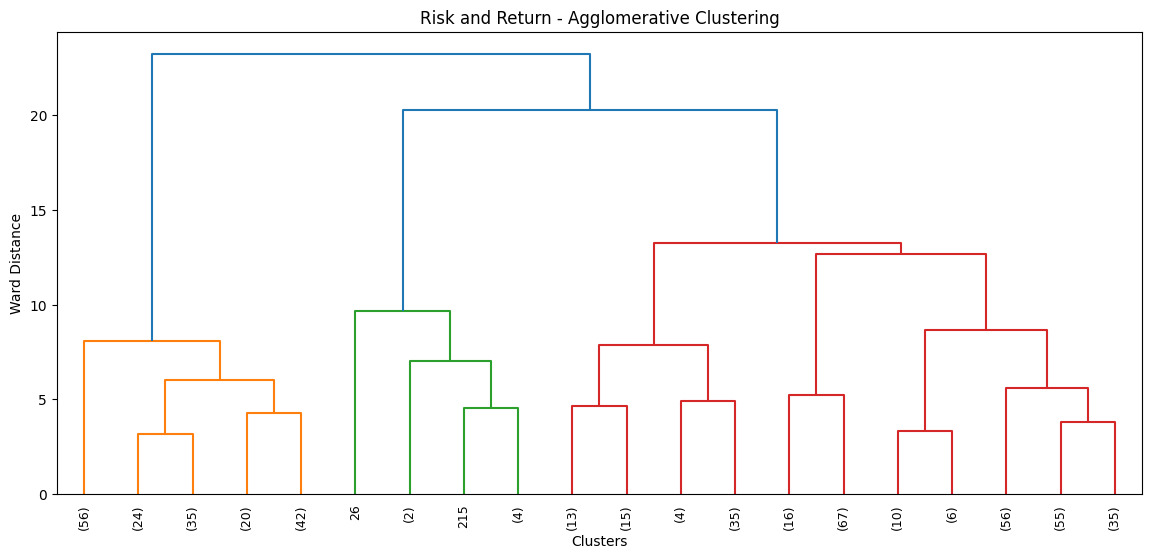

In [88]:
plt.figure(figsize=(14, 6))

dendrogram(
    risk_linkage,
    truncate_mode="lastp",
    p=20,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Risk and Return - Agglomerative Clustering")
plt.xlabel("Clusters")
plt.ylabel("Ward Distance")
plt.show()

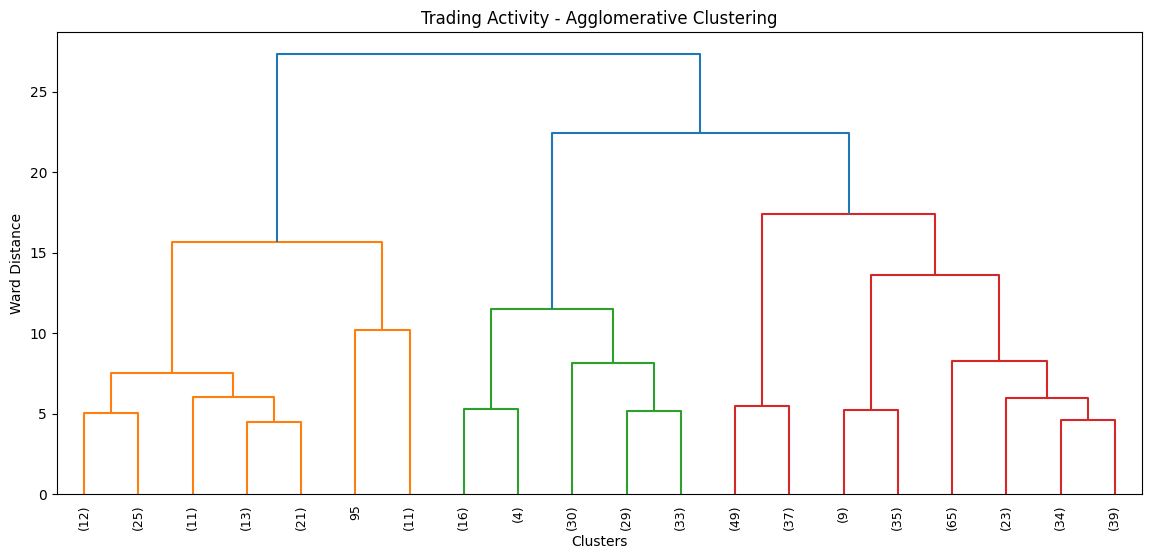

In [89]:
plt.figure(figsize=(14, 6))

dendrogram(
    activity_linkage,
    truncate_mode="lastp",
    p=20,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Trading Activity - Agglomerative Clustering")
plt.xlabel("Clusters")
plt.ylabel("Ward Distance")
plt.show()

In [90]:
risk_silhouette = []
activity_silhouette = []

for k in range(2, 9):

    risk_model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    risk_labels = risk_model.fit_predict(risk_return_scaled)

    activity_model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    activity_labels = activity_model.fit_predict(trading_activity_scaled)

    risk_silhouette.append(
        silhouette_score(risk_return_scaled, risk_labels)
    )

    activity_silhouette.append(
        silhouette_score(trading_activity_scaled, activity_labels)
    )

In [91]:
silhouette_results = pd.DataFrame({
    "Number of Clusters": range(2, 9),
    "Risk and Return": risk_silhouette,
    "Trading Activity": activity_silhouette
})

display(silhouette_results)

,Number of Clusters,Risk and Return,Trading Activity
0,2,0.288400,0.358097
1,3,0.320226,0.303209
2,4,0.296645,0.256015
3,5,0.288629,0.278435
4,6,0.289676,0.288176
5,7,0.296673,0.306281
6,8,0.279126,0.308065


In [92]:
risk_cluster_sizes = {}
activity_cluster_sizes = {}

for k in range(2, 9):

    risk_model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    risk_labels = risk_model.fit_predict(risk_return_scaled)

    activity_model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    activity_labels = activity_model.fit_predict(trading_activity_scaled)

    risk_cluster_sizes[k] = pd.Series(risk_labels).value_counts().sort_index().values
    activity_cluster_sizes[k] = pd.Series(activity_labels).value_counts().sort_index().values

    print(f"\nNumber of clusters: {k}")
    print("Risk and Return:", risk_cluster_sizes[k])
    print("Trading Activity:", activity_cluster_sizes[k])


Number of clusters: 2
Risk and Return: [320 177]
Trading Activity: [403  94]

Number of clusters: 3
Risk and Return: [312 177   8]
Trading Activity: [291  94 112]

Number of clusters: 4
Risk and Return: [245 177   8  67]
Trading Activity: [ 94 205 112  86]

Number of clusters: 5
Risk and Return: [  8 177 162  67  83]
Trading Activity: [205  12 112  86  82]

Number of clusters: 6
Risk and Return: [162 177   7  67  83   1]
Trading Activity: [112  12 161  86  82  44]

Number of clusters: 7
Risk and Return: [177  67   7 146  83   1  16]
Trading Activity: [ 12  92 161  86  82  44  20]

Number of clusters: 8
Risk and Return: [ 67 121   7 146  83   1  16  56]
Trading Activity: [161  92  20  86  82  44  11   1]


In [93]:
risk_model_2 = AgglomerativeClustering(
    n_clusters=2, linkage="ward"
)
risk_model_3 = AgglomerativeClustering(
    n_clusters=3, linkage="ward"
)

activity_model_2 = AgglomerativeClustering(
    n_clusters=2, linkage="ward"
)
activity_model_3 = AgglomerativeClustering(
    n_clusters=3, linkage="ward"
)

risk_labels_2 = risk_model_2.fit_predict(risk_return_scaled)
risk_labels_3 = risk_model_3.fit_predict(risk_return_scaled)

activity_labels_2 = activity_model_2.fit_predict(trading_activity_scaled)
activity_labels_3 = activity_model_3.fit_predict(trading_activity_scaled)

In [94]:
# Create cluster profiles using original feature values

risk_agglomerative_profile = risk_return_features.copy()
risk_agglomerative_profile["Cluster"] = risk_labels_2

activity_agglomerative_profile = trading_activity_features.copy()
activity_agglomerative_profile["Cluster"] = activity_labels_2

print("Risk and Return Profiles")
display(
    risk_agglomerative_profile.groupby("Cluster").mean().round(4)
)

print("Trading Activity Profiles")
display(
    activity_agglomerative_profile.groupby("Cluster").mean().round(2)
)

Risk and Return Profiles


,Mean_Weekly_Return,Weekly_Beta
Cluster,,
0,0.0036,1.2080
1,0.0021,0.5789


Trading Activity Profiles


,Recency,Frequency,Monetary
Cluster,,,
0,12.36,3.22,23.66
1,55.53,2.07,23.81


In [95]:
agglomerative_results = pd.DataFrame(
    index=risk_return_features.index
)

agglomerative_results["Risk_Return_Cluster"] = risk_labels_2
agglomerative_results["Trading_Activity_Cluster"] = activity_labels_2

display(agglomerative_results.head())

,Risk_Return_Cluster,Trading_Activity_Cluster
NWSA,0,0
JNJ,1,0
CDW,0,1
AES,0,1
VMC,0,0


2.3

In [96]:
inertia_risk = []
inertia_activity = []

for k in range(2, 9):

    risk_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    risk_kmeans.fit(risk_return_scaled)
    inertia_risk.append(risk_kmeans.inertia_)

    activity_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    activity_kmeans.fit(trading_activity_scaled)
    inertia_activity.append(activity_kmeans.inertia_)

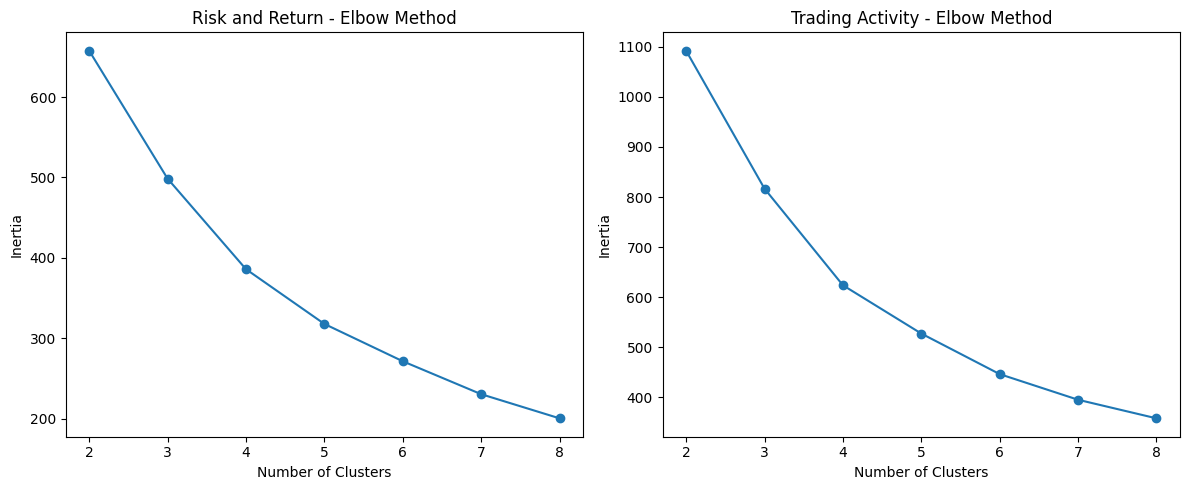

In [97]:
cluster_range = range(2, 9)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(cluster_range, inertia_risk, marker="o")
plt.title("Risk and Return - Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(cluster_range, inertia_activity, marker="o")
plt.title("Trading Activity - Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.tight_layout()
plt.show()

In [98]:
kmeans_risk_silhouette = []
kmeans_activity_silhouette = []

for k in range(2, 9):

    risk_kmeans = KMeans(
        n_clusters=k, random_state=42, n_init=10
    )
    risk_labels = risk_kmeans.fit_predict(risk_return_scaled)

    activity_kmeans = KMeans(
        n_clusters=k, random_state=42, n_init=10
    )
    activity_labels = activity_kmeans.fit_predict(trading_activity_scaled)

    kmeans_risk_silhouette.append(
        silhouette_score(risk_return_scaled, risk_labels)
    )

    kmeans_activity_silhouette.append(
        silhouette_score(trading_activity_scaled, activity_labels)
    )

In [99]:
kmeans_silhouette_results = pd.DataFrame({
    "Number of Clusters": range(2, 9),
    "Risk and Return": kmeans_risk_silhouette,
    "Trading Activity": kmeans_activity_silhouette
})

display(kmeans_silhouette_results)

,Number of Clusters,Risk and Return,Trading Activity
0,2,0.400138,0.418414
1,3,0.344313,0.323988
2,4,0.336652,0.340421
3,5,0.330883,0.356659
4,6,0.349735,0.345764
5,7,0.337091,0.348976
6,8,0.339358,0.326398


In [100]:
for k in range(2, 9):

    risk_model = KMeans(
        n_clusters=k, random_state=42, n_init=10
    )
    risk_labels = risk_model.fit_predict(risk_return_scaled)

    activity_model = KMeans(
        n_clusters=k, random_state=42, n_init=10
    )
    activity_labels = activity_model.fit_predict(trading_activity_scaled)

    print(f"\nNumber of clusters: {k}")
    print("Risk and Return:",
          pd.Series(risk_labels).value_counts().sort_index().values)
    print("Trading Activity:",
          pd.Series(activity_labels).value_counts().sort_index().values)


Number of clusters: 2
Risk and Return: [147 350]
Trading Activity: [ 72 425]

Number of clusters: 3
Risk and Return: [276 206  15]
Trading Activity: [275 157  65]

Number of clusters: 4
Risk and Return: [176 192 121   8]
Trading Activity: [215  96 124  62]

Number of clusters: 5
Risk and Return: [168  43 126 158   2]
Trading Activity: [ 91  11 124 201  70]

Number of clusters: 6
Risk and Return: [ 58 185   1   8 140 105]
Trading Activity: [122  11 144  70 107  43]

Number of clusters: 7
Risk and Return: [148 108  53   2  93  17  76]
Trading Activity: [121  11 105  43 145  71   1]

Number of clusters: 8
Risk and Return: [ 90  30  49   2  89 152   7  78]
Trading Activity: [ 63  79 115  14  23 119  83   1]


In [101]:
# Fit final K-means models

risk_kmeans_final = KMeans(
    n_clusters=2, random_state=42, n_init=10
)
risk_kmeans_labels = risk_kmeans_final.fit_predict(risk_return_scaled)

activity_kmeans_final = KMeans(
    n_clusters=2, random_state=42, n_init=10
)
activity_kmeans_labels = activity_kmeans_final.fit_predict(trading_activity_scaled)


# Create cluster profiles using original feature values

risk_kmeans_profile = risk_return_features.copy()
risk_kmeans_profile["Cluster"] = risk_kmeans_labels

activity_kmeans_profile = trading_activity_features.copy()
activity_kmeans_profile["Cluster"] = activity_kmeans_labels

print("Risk and Return Profiles")
display(risk_kmeans_profile.groupby("Cluster").mean().round(4))

print("Trading Activity Profiles")
display(activity_kmeans_profile.groupby("Cluster").mean().round(2))

Risk and Return Profiles


,Mean_Weekly_Return,Weekly_Beta
Cluster,,
0,0.0054,1.4274
1,0.0020,0.7977


Trading Activity Profiles


,Recency,Frequency,Monetary
Cluster,,,
0,62.49,1.85,23.96
1,13.42,3.20,23.65


In [102]:
kmeans_results = pd.DataFrame(
    index=risk_return_features.index
)

kmeans_results["Risk_Return_Cluster"] = risk_kmeans_labels
kmeans_results["Trading_Activity_Cluster"] = activity_kmeans_labels

display(kmeans_results.head())

,Risk_Return_Cluster,Trading_Activity_Cluster
NWSA,1,1
JNJ,1,1
CDW,1,0
AES,1,0
VMC,1,1


2.4

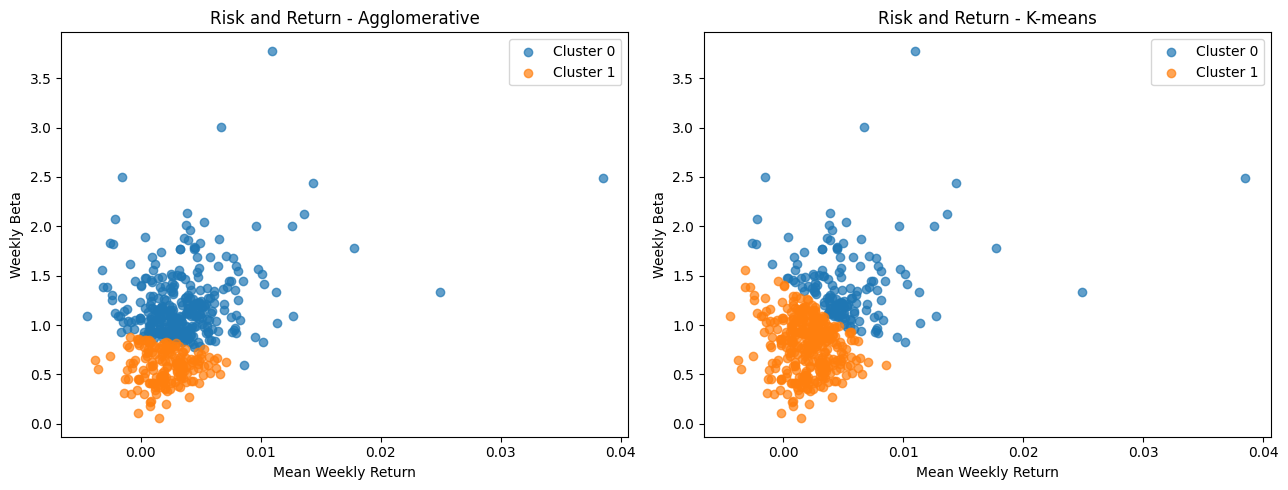

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for cluster in sorted(agglomerative_results["Risk_Return_Cluster"].unique()):
    mask = agglomerative_results["Risk_Return_Cluster"] == cluster
    axes[0].scatter(
        risk_return_features.loc[mask, "Mean_Weekly_Return"],
        risk_return_features.loc[mask, "Weekly_Beta"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

axes[0].set_title("Risk and Return - Agglomerative")
axes[0].set_xlabel("Mean Weekly Return")
axes[0].set_ylabel("Weekly Beta")
axes[0].legend()

for cluster in sorted(kmeans_results["Risk_Return_Cluster"].unique()):
    mask = kmeans_results["Risk_Return_Cluster"] == cluster
    axes[1].scatter(
        risk_return_features.loc[mask, "Mean_Weekly_Return"],
        risk_return_features.loc[mask, "Weekly_Beta"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

axes[1].set_title("Risk and Return - K-means")
axes[1].set_xlabel("Mean Weekly Return")
axes[1].set_ylabel("Weekly Beta")
axes[1].legend()

plt.tight_layout()
plt.show()

In [104]:
pca = PCA(n_components=2)

activity_pca = pca.fit_transform(trading_activity_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.45655201 0.33903362]
Total variance explained: 0.7955856283985813


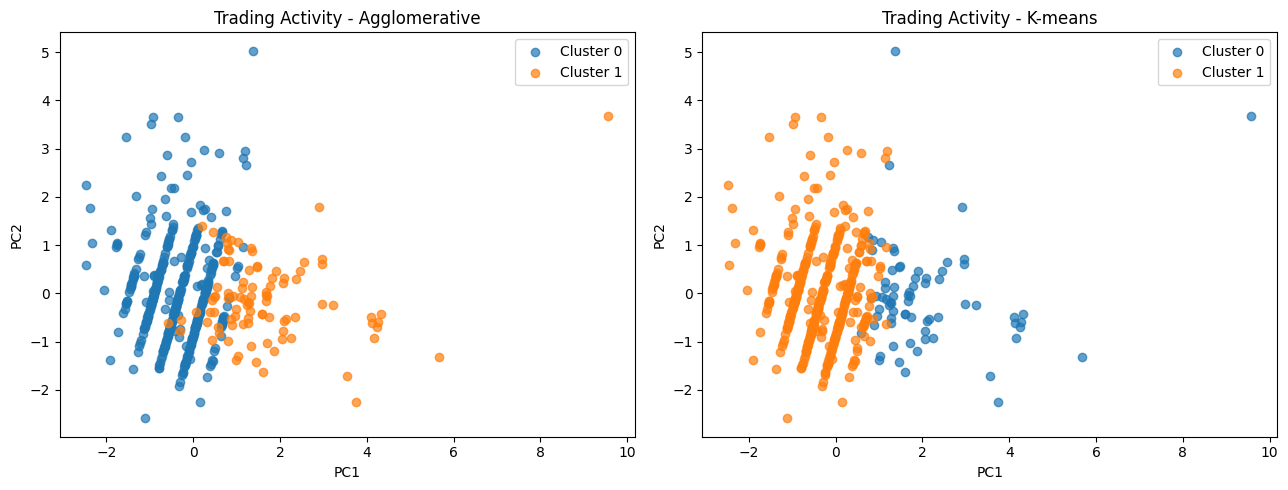

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Agglomerative
for cluster in sorted(agglomerative_results["Trading_Activity_Cluster"].unique()):
    mask = agglomerative_results["Trading_Activity_Cluster"] == cluster

    axes[0].scatter(
        activity_pca[mask, 0],
        activity_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

axes[0].set_title("Trading Activity - Agglomerative")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()

# K-means
for cluster in sorted(kmeans_results["Trading_Activity_Cluster"].unique()):
    mask = kmeans_results["Trading_Activity_Cluster"] == cluster

    axes[1].scatter(
        activity_pca[mask, 0],
        activity_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

axes[1].set_title("Trading Activity - K-means")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend()

plt.tight_layout()
plt.show()

In [106]:
from sklearn.metrics import adjusted_rand_score

In [107]:
risk_ari = adjusted_rand_score(
    agglomerative_results["Risk_Return_Cluster"],
    kmeans_results["Risk_Return_Cluster"]
)

activity_ari = adjusted_rand_score(
    agglomerative_results["Trading_Activity_Cluster"],
    kmeans_results["Trading_Activity_Cluster"]
)

print("Risk and Return ARI:", round(risk_ari, 4))
print("Trading Activity ARI:", round(activity_ari, 4))

Risk and Return ARI: 0.0782
Trading Activity ARI: 0.7535


2.5

In [108]:
rfm_correlation = trading_activity_features.rename(
    columns={"Monetary": "log1p(M)"}
).corr()

print("RFM Feature Correlation Matrix")
display(rfm_correlation.round(3))

RFM Feature Correlation Matrix


,Recency,Frequency,log1p(M)
Recency,1.000,-0.340,0.164
Frequency,-0.340,1.000,0.022
log1p(M),0.164,0.022,1.000


In [109]:
rf_features = trading_activity_features[
    ["Recency", "Frequency"]
].copy()

scaler_rf = StandardScaler()
rf_scaled = scaler_rf.fit_transform(rf_features)

print("Reduced feature matrix shape:", rf_scaled.shape)

Reduced feature matrix shape: (497, 2)


In [110]:
from scipy.cluster.hierarchy import fcluster

In [111]:
rf_linkage = linkage(
    rf_scaled,
    method="ward",
    metric="euclidean"
)

rf_labels_2 = fcluster(
    rf_linkage,
    t=2,
    criterion="maxclust"
) - 1

print("Cluster sizes:")
print(pd.Series(rf_labels_2).value_counts().sort_index())

Cluster sizes:
0     93
1    404
Name: count, dtype: int64


In [112]:
rfm_ari = adjusted_rand_score(
    activity_labels_2,
    rf_labels_2
)

print("RFM vs RF ARI:", round(rfm_ari, 4))

RFM vs RF ARI: 0.953


In [113]:
rfm_monetary_profiles = pd.DataFrame({
    "Monetary": np.expm1(trading_activity_features["Monetary"]),
    "Cluster": activity_labels_2
})

print("Original RFM - Traded Value Profiles")
display(
    rfm_monetary_profiles.groupby("Cluster")["Monetary"]
    .mean().round(2)
)

Original RFM - Traded Value Profiles


,Monetary
Cluster,
0,3.827618e+10
1,4.565006e+10


In [114]:
rf_monetary_profiles = pd.DataFrame({
    "Monetary": np.expm1(trading_activity_features["Monetary"]),
    "Cluster": rf_labels_2
})

print("Reduced R/F - Traded Value Profiles")

display(
    rf_monetary_profiles.groupby("Cluster")["Monetary"]
    .mean().round(2)
)

Reduced R/F - Traded Value Profiles


,Monetary
Cluster,
0,4.799647e+10
1,3.775429e+10


In [115]:
# Risk and Return cluster assignments
risk_cluster_assignments = pd.DataFrame({
    "Ticker": risk_return_features.index,
    "Agglomerative_Cluster": risk_labels_2,
    "KMeans_Cluster": risk_kmeans_labels
})

# Trading Activity cluster assignments
activity_cluster_assignments = pd.DataFrame({
    "Ticker": trading_activity_features.index,
    "Agglomerative_Cluster": activity_labels_2,
    "KMeans_Cluster": activity_kmeans_labels
})

print("Risk and Return Cluster Assignments")
display(risk_cluster_assignments)

print("Trading Activity Cluster Assignments")
display(activity_cluster_assignments)


Risk and Return Cluster Assignments


,Ticker,Agglomerative_Cluster,KMeans_Cluster
0,NWSA,0,1
1,JNJ,1,1
2,CDW,0,1
3,AES,0,1
4,VMC,0,1
...,...,...,...
492,KR,1,1
493,ESS,1,1
494,MGM,0,0
495,TPR,0,0


Trading Activity Cluster Assignments


,Ticker,Agglomerative_Cluster,KMeans_Cluster
0,NWSA,0,1
1,JNJ,0,1
2,CDW,1,0
3,AES,1,0
4,VMC,0,1
...,...,...,...
492,KR,0,1
493,ESS,0,1
494,MGM,0,1
495,TPR,0,1


In [116]:
risk_cluster_assignments.to_csv(
    "risk_return_cluster_assignments.csv", index=False
)

activity_cluster_assignments.to_csv(
    "trading_activity_cluster_assignments.csv", index=False
)

3.2 Sector Analysis

In [117]:
# Prepare sector and company lookup dataset
sector_data = sp500_tickers.rename(
    columns={"Symbol": "Ticker"}
).copy()

# Standardise ticker symbols
sector_data["Ticker"] = sector_data["Ticker"].str.replace(
    ".", "-", regex=False
)

display(sector_data.head())

,Ticker,Company,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


In [118]:
# Prepare company and sector reference data
sector_data = sp500_tickers.rename(
    columns={"Symbol": "Ticker"}
).copy()

# Standardise ticker symbols to match Yahoo Finance
sector_data["Ticker"] = sector_data["Ticker"].str.replace(
    ".", "-", regex=False
)

# Merge sector information with Risk and Return clusters
risk_sector = risk_cluster_assignments.merge(
    sector_data,
    on="Ticker",
    how="left"
)

# Merge sector information with Trading Activity clusters
activity_sector = activity_cluster_assignments.merge(
    sector_data,
    on="Ticker",
    how="left"
)

# Check merge results
print("Risk and Return:")
print("Number of stocks:", len(risk_sector))
print("Missing sectors:", risk_sector["GICS Sector"].isna().sum())

print("\nTrading Activity:")
print("Number of stocks:", len(activity_sector))
print("Missing sectors:", activity_sector["GICS Sector"].isna().sum())

display(risk_sector.head())
display(activity_sector.head())

Risk and Return:
Number of stocks: 497
Missing sectors: 0

Trading Activity:
Number of stocks: 497
Missing sectors: 0


,Ticker,Agglomerative_Cluster,KMeans_Cluster,Company,GICS Sector
0,NWSA,0,1,News Corp (Class A),Communication Services
1,JNJ,1,1,Johnson & Johnson,Health Care
2,CDW,0,1,CDW Corporation,Information Technology
3,AES,0,1,AES Corporation,Utilities
4,VMC,0,1,Vulcan Materials Company,Materials


,Ticker,Agglomerative_Cluster,KMeans_Cluster,Company,GICS Sector
0,NWSA,0,1,News Corp (Class A),Communication Services
1,JNJ,0,1,Johnson & Johnson,Health Care
2,CDW,1,0,CDW Corporation,Information Technology
3,AES,1,0,AES Corporation,Utilities
4,VMC,0,1,Vulcan Materials Company,Materials


In [119]:
# Risk and Return - Agglomerative
risk_agg_sector = pd.crosstab(
    risk_sector["Agglomerative_Cluster"],
    risk_sector["GICS Sector"]
)

# Risk and Return - K-Means
risk_kmeans_sector = pd.crosstab(
    risk_sector["KMeans_Cluster"],
    risk_sector["GICS Sector"]
)

# Trading Activity - Agglomerative
activity_agg_sector = pd.crosstab(
    activity_sector["Agglomerative_Cluster"],
    activity_sector["GICS Sector"]
)

# Trading Activity - K-Means
activity_kmeans_sector = pd.crosstab(
    activity_sector["KMeans_Cluster"],
    activity_sector["GICS Sector"]
)

# Display sector counts
print("Risk and Return - Agglomerative")
display(risk_agg_sector)

print("Risk and Return - K-Means")
display(risk_kmeans_sector)

print("Trading Activity - Agglomerative")
display(activity_agg_sector)

print("Trading Activity - K-Means")
display(activity_kmeans_sector)

Risk and Return - Agglomerative


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Agglomerative_Cluster,,,,,,,,,,,
0,13,40,4,11,53,29,63,70,14,19,4
1,9,7,28,10,23,31,18,4,9,11,27


Risk and Return - K-Means


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Cluster,,,,,,,,,,,
0,7,21,1,5,20,2,28,52,5,3,3
1,15,26,31,16,56,58,53,22,18,27,28


Trading Activity - Agglomerative


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Agglomerative_Cluster,,,,,,,,,,,
0,18,37,24,19,62,51,72,54,15,30,21
1,4,10,8,2,14,9,9,20,8,0,10


Trading Activity - K-Means


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Cluster,,,,,,,,,,,
0,2,8,5,1,12,8,5,15,6,0,10
1,20,39,27,20,64,52,76,59,17,30,21


In [120]:
# Calculate sector percentages within each cluster
def sector_percentages(data):
    return data.div(data.sum(axis=1), axis=0) * 100


risk_agg_percentage = sector_percentages(risk_agg_sector)
risk_kmeans_percentage = sector_percentages(risk_kmeans_sector)

activity_agg_percentage = sector_percentages(activity_agg_sector)
activity_kmeans_percentage = sector_percentages(activity_kmeans_sector)

# Display percentage tables
print("Risk and Return - Agglomerative (%)")
display(risk_agg_percentage.round(2))

print("Risk and Return - K-Means (%)")
display(risk_kmeans_percentage.round(2))

print("Trading Activity - Agglomerative (%)")
display(activity_agg_percentage.round(2))

print("Trading Activity - K-Means (%)")
display(activity_kmeans_percentage.round(2))

Risk and Return - Agglomerative (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Agglomerative_Cluster,,,,,,,,,,,
0,4.06,12.50,1.25,3.44,16.56,9.06,19.69,21.88,4.38,5.94,1.25
1,5.08,3.95,15.82,5.65,12.99,17.51,10.17,2.26,5.08,6.21,15.25


Risk and Return - K-Means (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Cluster,,,,,,,,,,,
0,4.76,14.29,0.68,3.40,13.61,1.36,19.05,35.37,3.40,2.04,2.04
1,4.29,7.43,8.86,4.57,16.00,16.57,15.14,6.29,5.14,7.71,8.00


Trading Activity - Agglomerative (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Agglomerative_Cluster,,,,,,,,,,,
0,4.47,9.18,5.96,4.71,15.38,12.66,17.87,13.40,3.72,7.44,5.21
1,4.26,10.64,8.51,2.13,14.89,9.57,9.57,21.28,8.51,0.00,10.64


Trading Activity - K-Means (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Cluster,,,,,,,,,,,
0,2.78,11.11,6.94,1.39,16.67,11.11,6.94,20.83,8.33,0.00,13.89
1,4.71,9.18,6.35,4.71,15.06,12.24,17.88,13.88,4.00,7.06,4.94


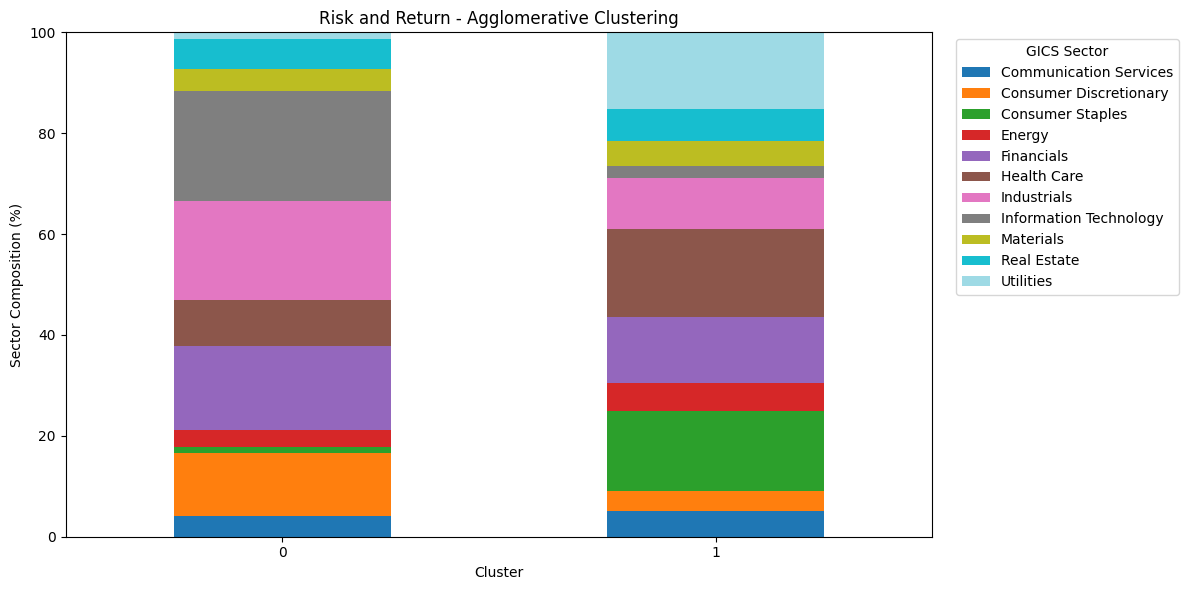

In [121]:
risk_agg_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("Risk and Return - Agglomerative Clustering")
plt.xlabel("Cluster")
plt.ylabel("Sector Composition (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="GICS Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

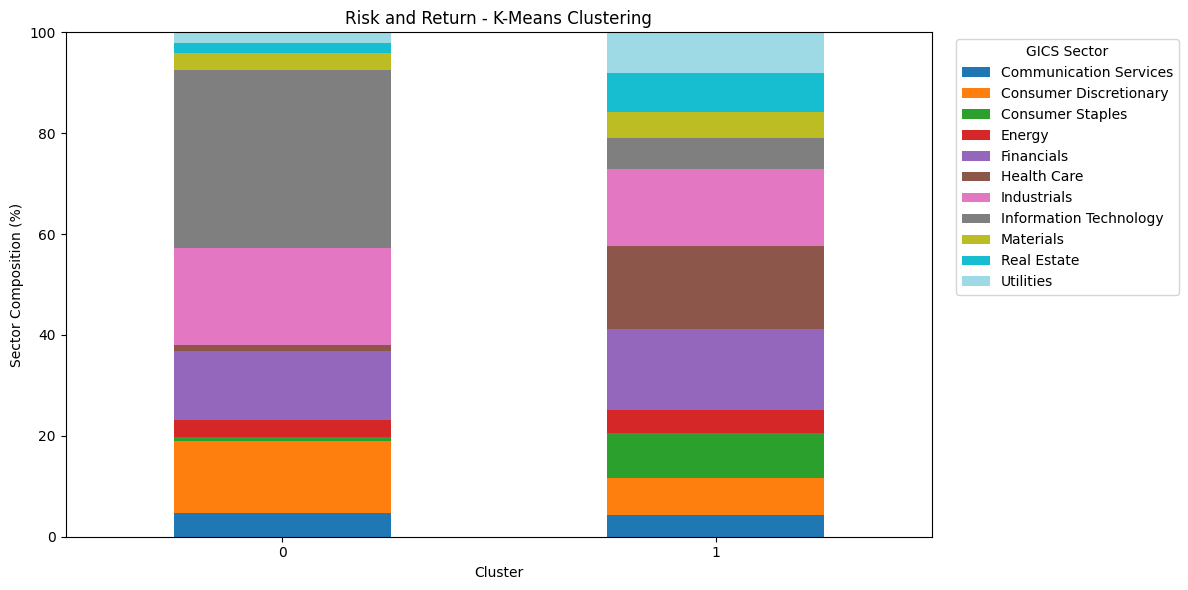

In [122]:
risk_kmeans_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("Risk and Return - K-Means Clustering")
plt.xlabel("Cluster")
plt.ylabel("Sector Composition (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="GICS Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

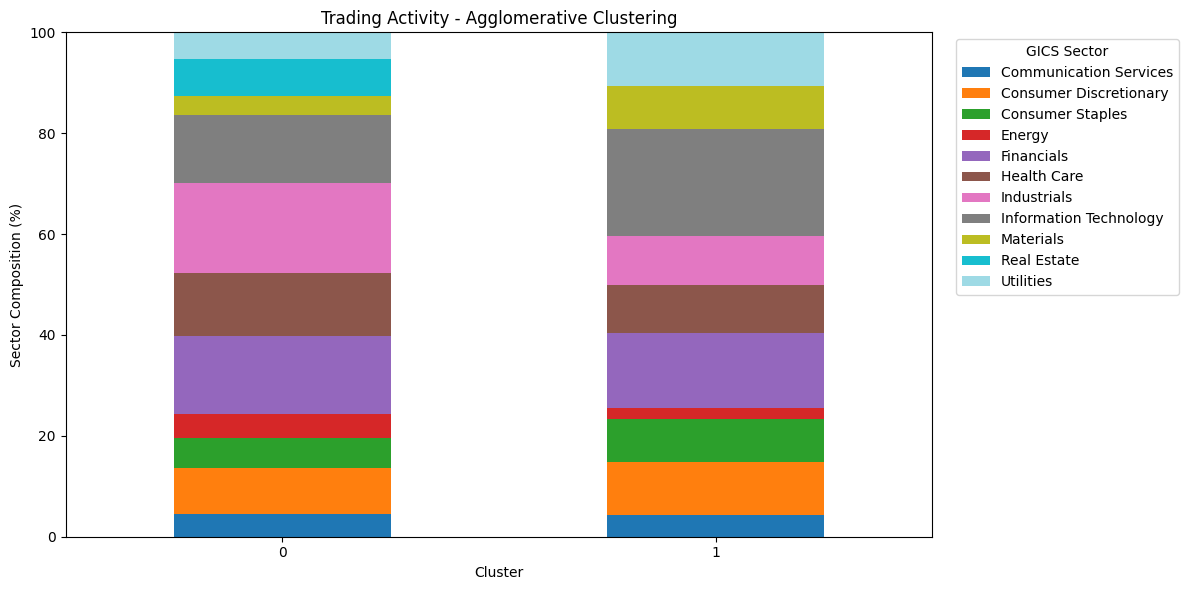

In [123]:
activity_agg_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("Trading Activity - Agglomerative Clustering")
plt.xlabel("Cluster")
plt.ylabel("Sector Composition (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="GICS Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

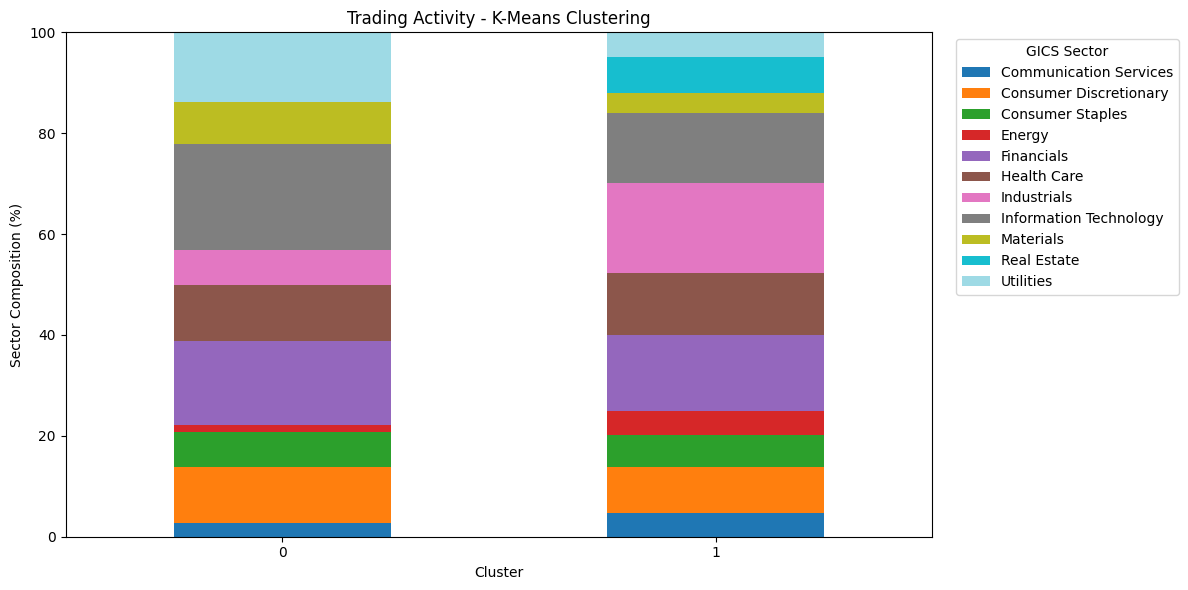

In [124]:
activity_kmeans_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("Trading Activity - K-Means Clustering")
plt.xlabel("Cluster")
plt.ylabel("Sector Composition (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="GICS Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [125]:
# Save the price data and feature tables
stock_data.to_csv("sp500_daily_prices.csv.gz")
all_features.to_csv("all_features.csv")
risk_return_features.to_csv("risk_return_features.csv")
trading_activity_features.to_csv("trading_activity_features.csv")